# Ambulance pooling vs Stovepipe — Delta heatmaps across distance space (2 ambulances)


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(_root / "data_cluster/resource_grid/results.csv")
df = df[df["n_amb_r1_to_ccp"] == 2].reset_index(drop=True)
print(f"Loaded {len(df)} runs (2 ambulances)")

MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]

stove = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)]
policy = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)]
print(f"Stovepipe: {len(stove)}, Ambulance pooling: {len(policy)}")
print(f"bcas rates: {sorted(df['bcas_rate'].unique())}")


Loaded 405600 runs (2 ambulances)
Stovepipe: 101400, Ambulance pooling: 101400
bcas rates: [np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07)]


## Fraction of seeds where amb pooling hurts (delta > 0) per distance cell


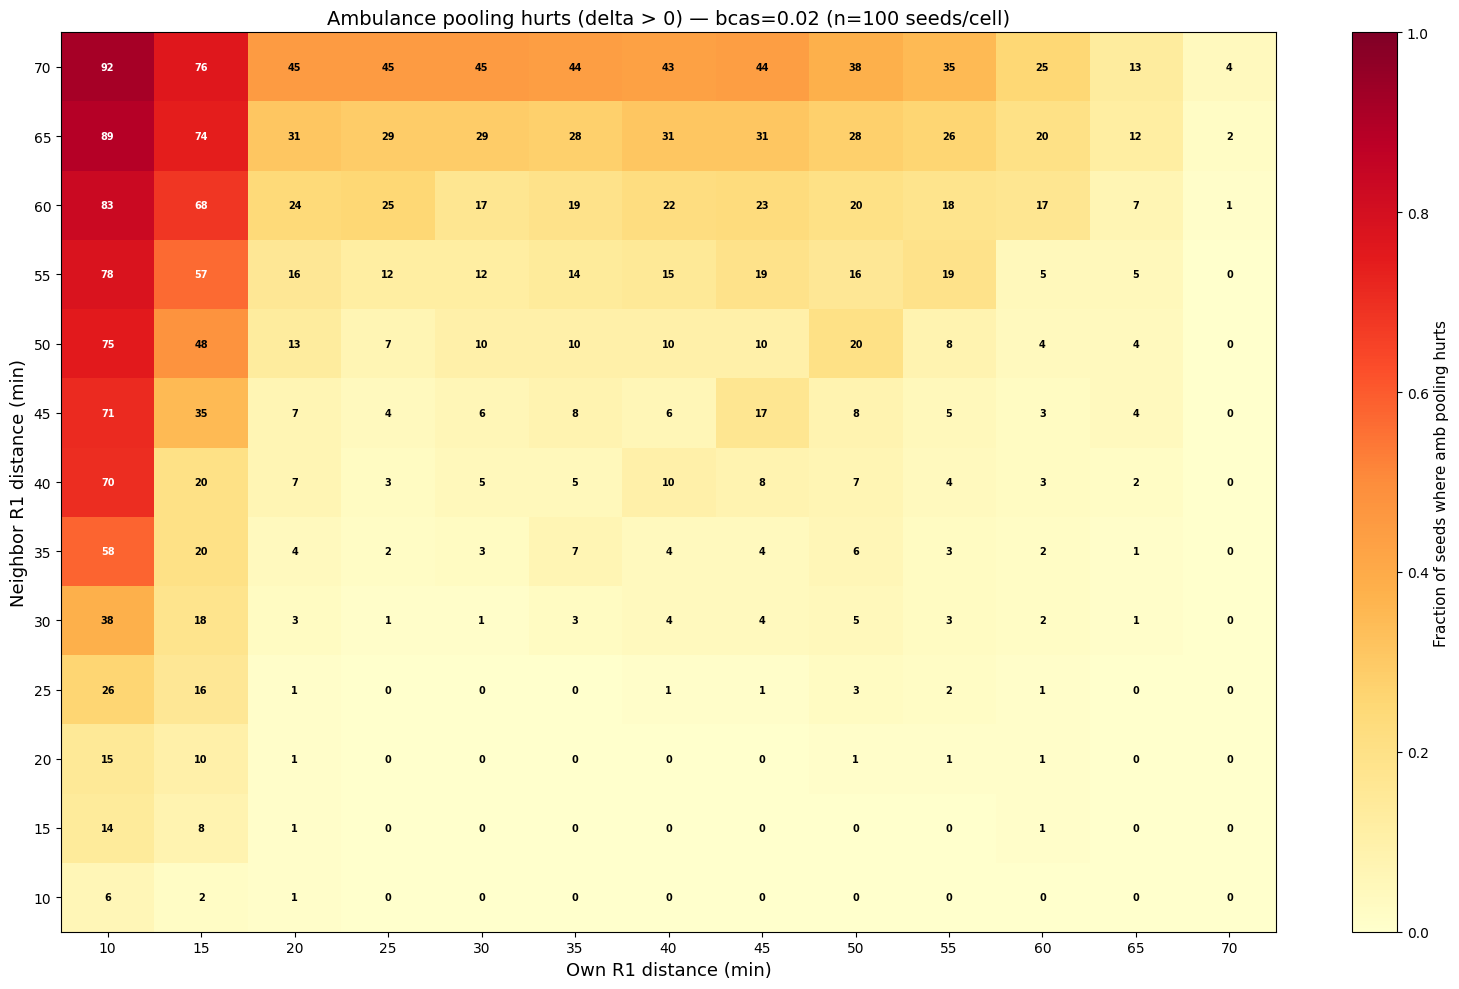

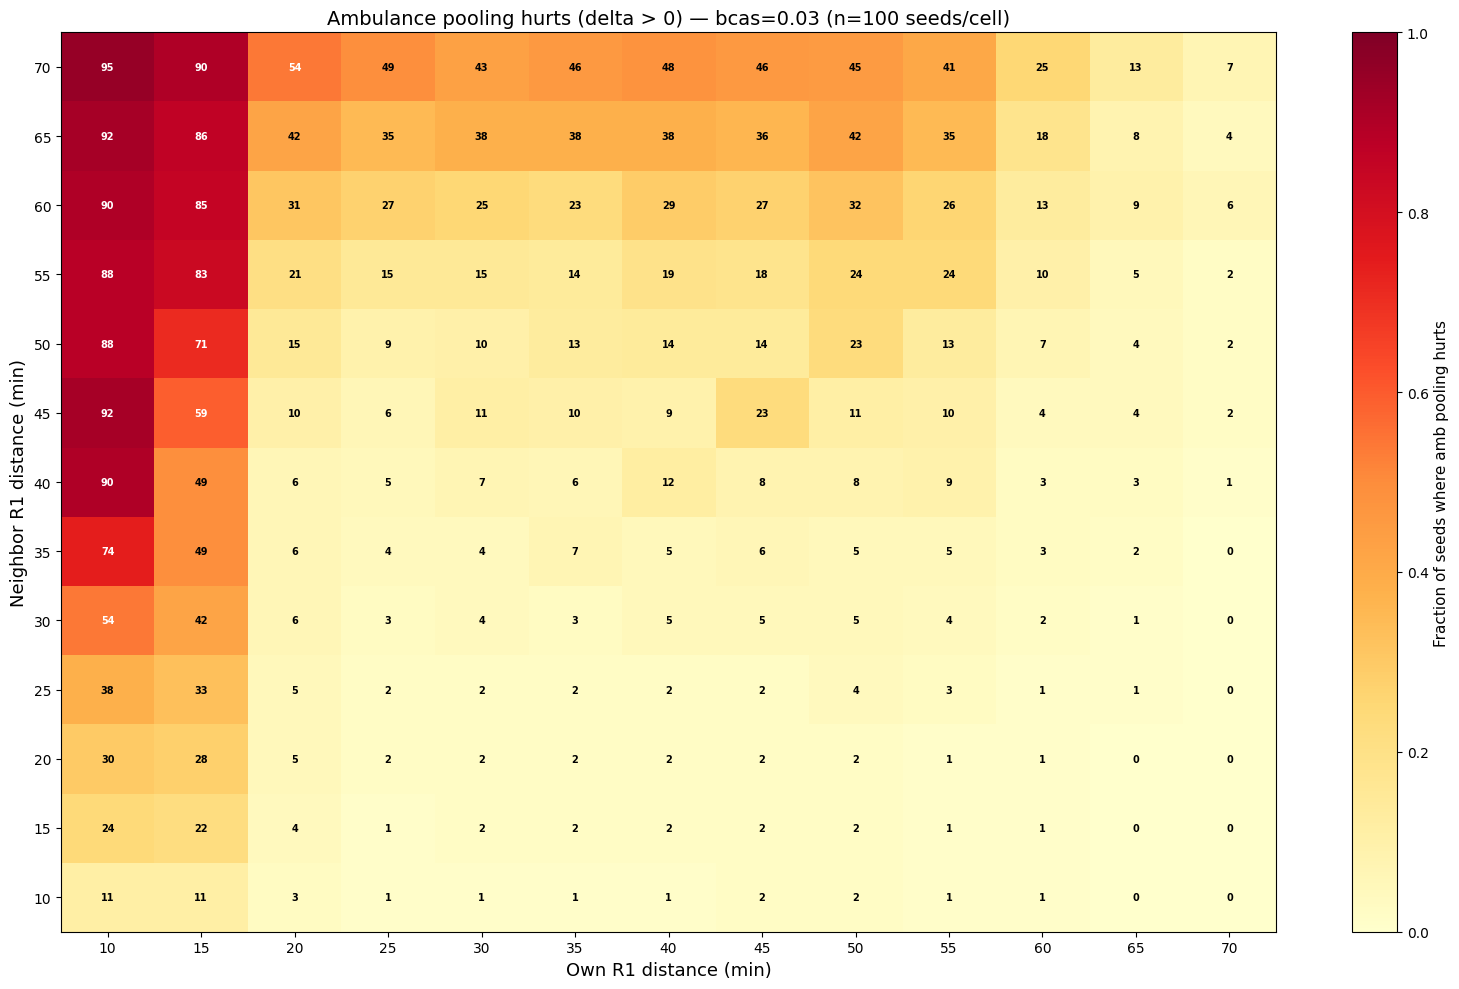

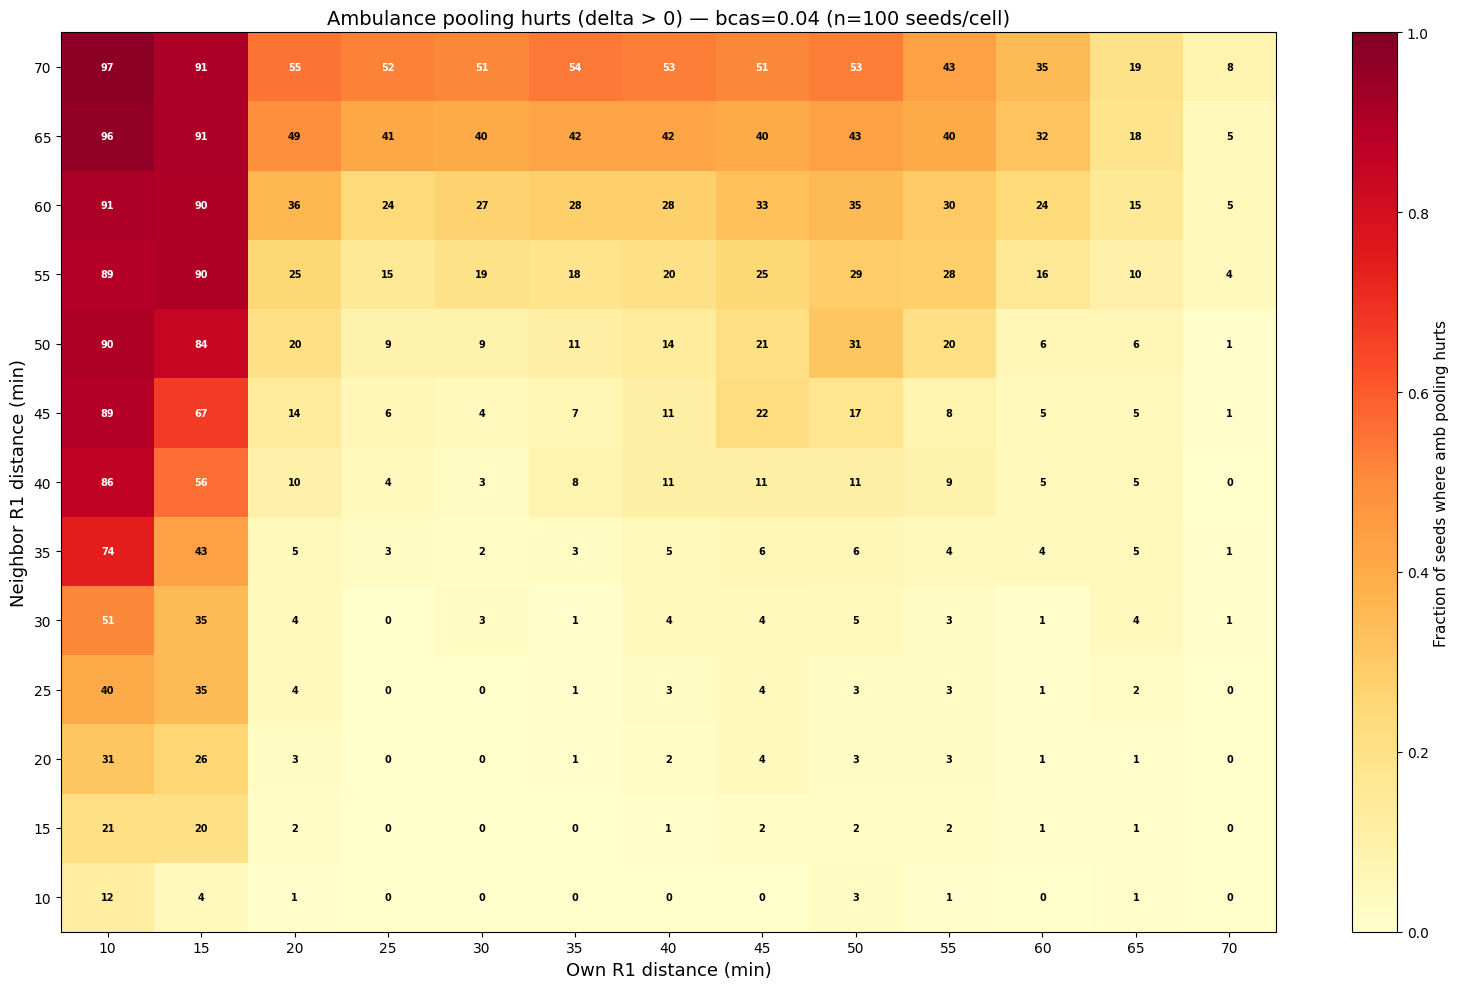

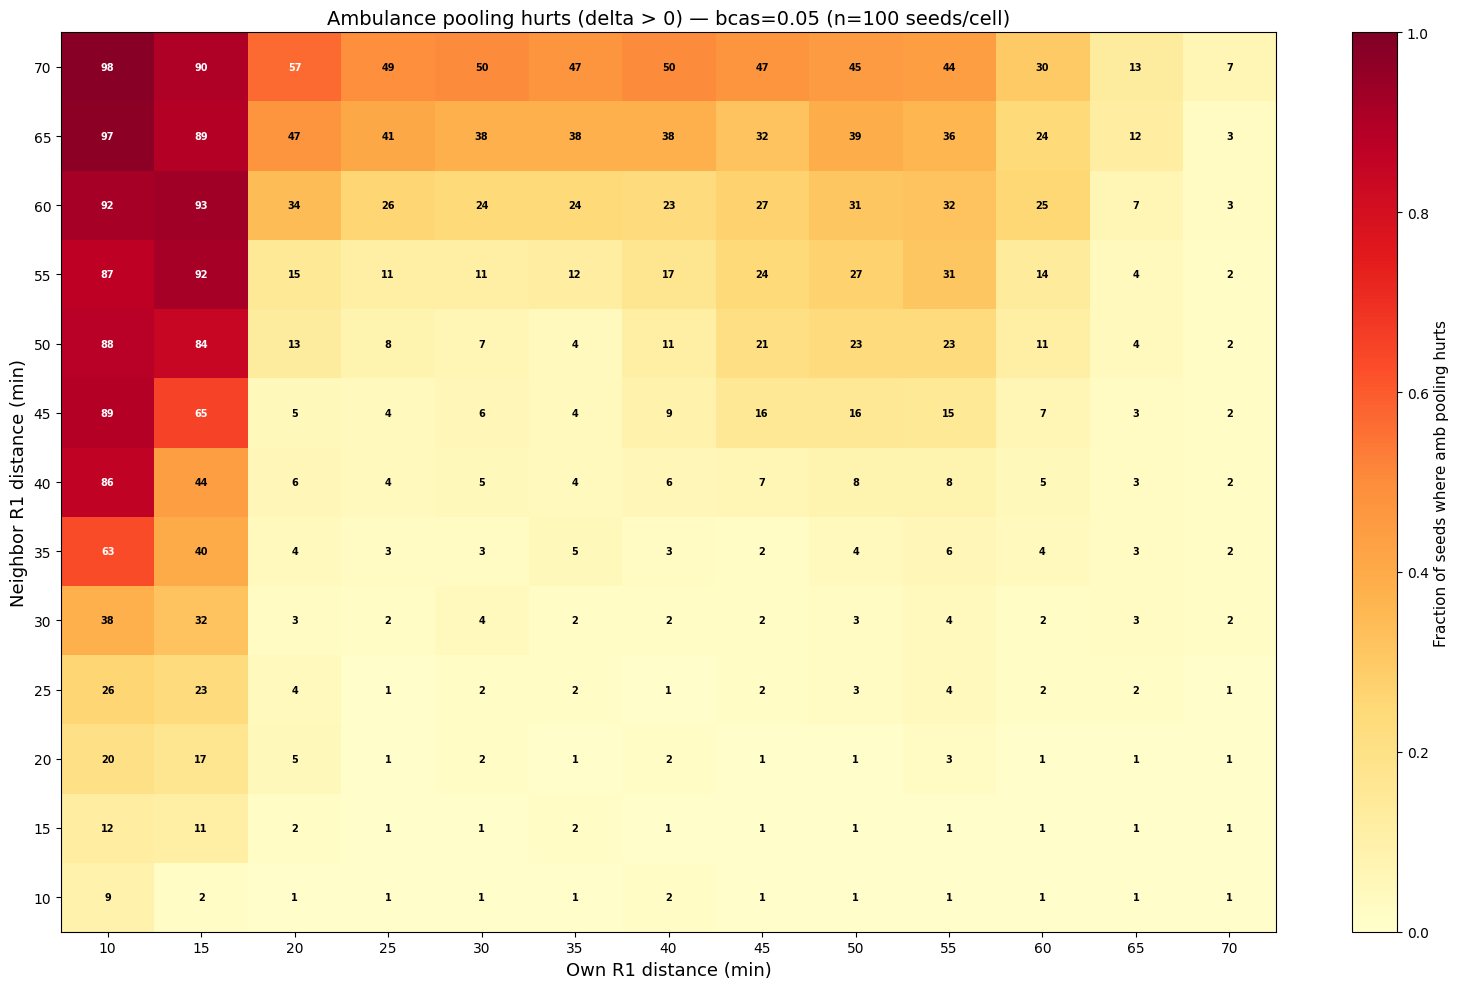

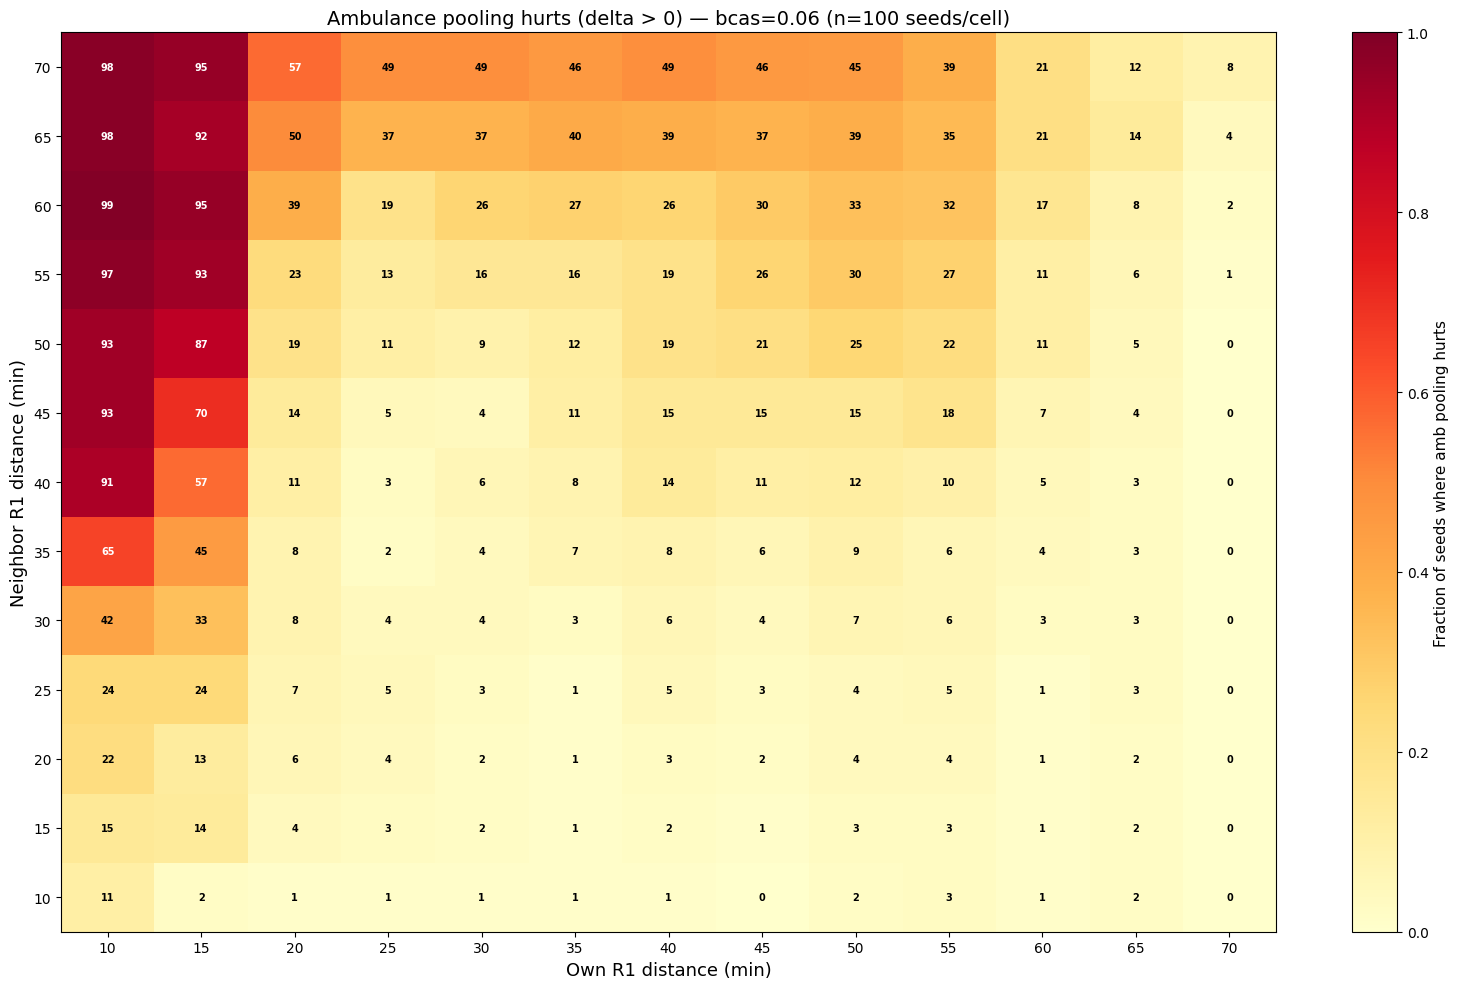

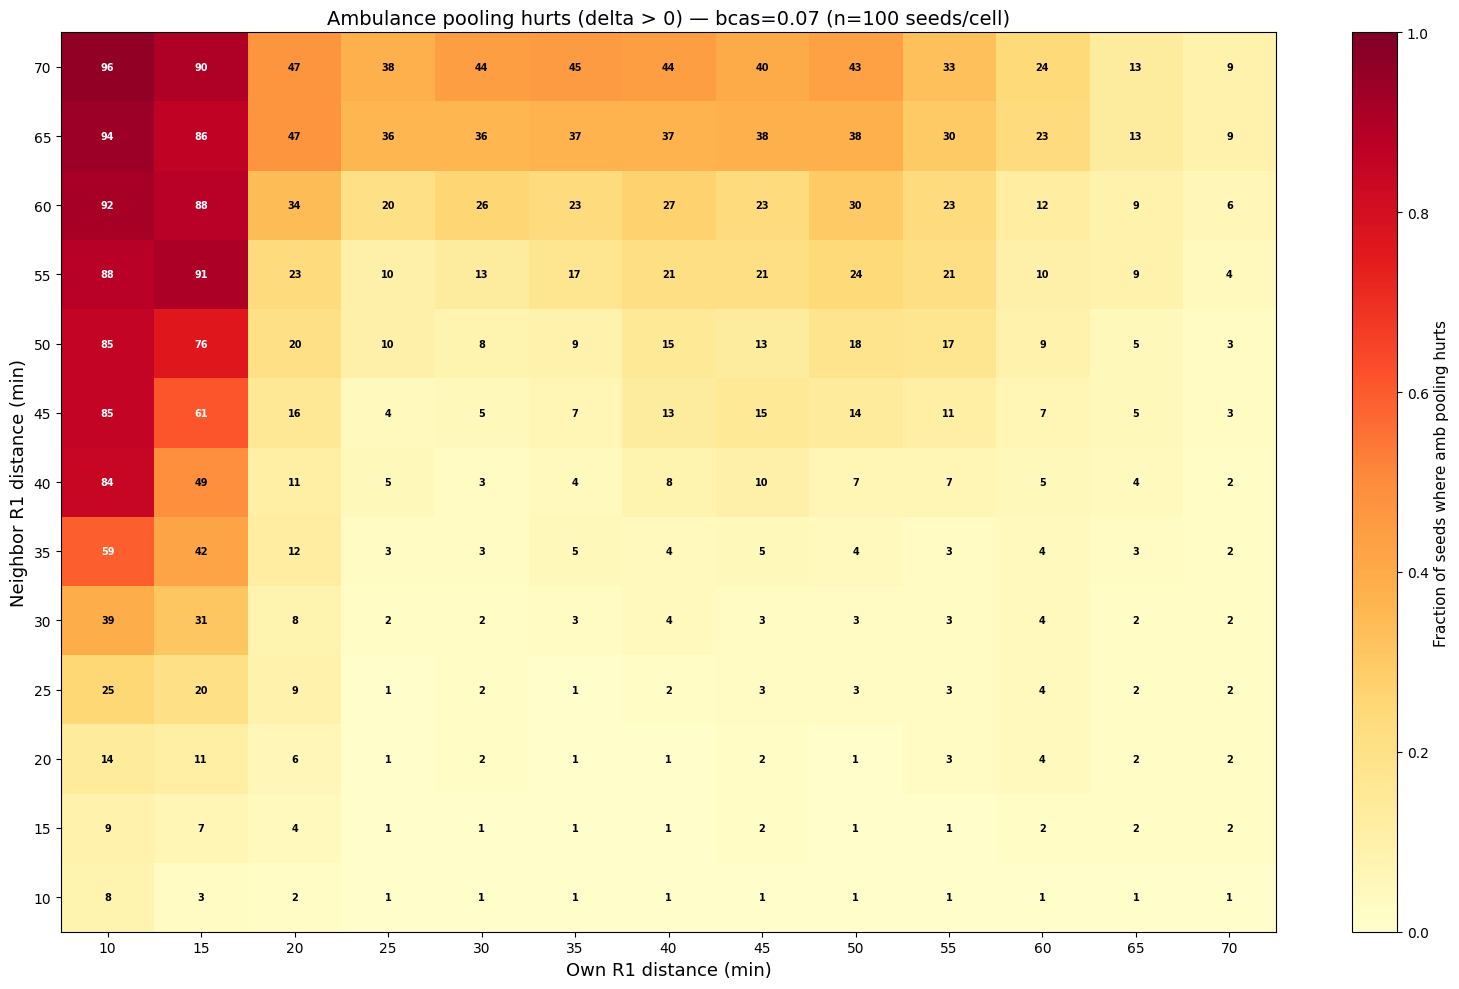

In [2]:
for bcas in sorted(df["bcas_rate"].unique()):
    s = stove[stove["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    p = policy[policy["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    assert (s[MATCH_COLS].values == p[MATCH_COLS].values).all()

    merged = s[MATCH_COLS].copy()
    merged["delta"] = p["death_rate_T1_BCAS"].values - s["death_rate_T1_BCAS"].values
    merged["hurts"] = merged["delta"] > 0

    grid = merged.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]).agg(
        frac_hurts=("hurts", "mean"),
        n_hurts=("hurts", "sum"),
        n_total=("hurts", "size"),
    ).reset_index()

    pivot_frac = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="frac_hurts")
    pivot_n = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="n_hurts")

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot_frac.values, cmap="YlOrRd", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=0, vmax=1)

    ax.set_xticks(range(len(pivot_frac.columns)))
    ax.set_xticklabels(pivot_frac.columns)
    ax.set_yticks(range(len(pivot_frac.index)))
    ax.set_yticklabels(pivot_frac.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Ambulance pooling hurts (delta > 0) — bcas={bcas} (n=100 seeds/cell)", fontsize=14)

    for i in range(len(pivot_frac.index)):
        for j in range(len(pivot_frac.columns)):
            frac = pivot_frac.values[i, j]
            n = int(pivot_n.values[i, j])
            color = "white" if frac > 0.5 else "black"
            ax.text(j, i, f"{n}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Fraction of seeds where amb pooling hurts", fontsize=11)
    plt.tight_layout()
    plt.show()


## Fraction of seeds where amb pooling helps (delta < 0) per distance cell


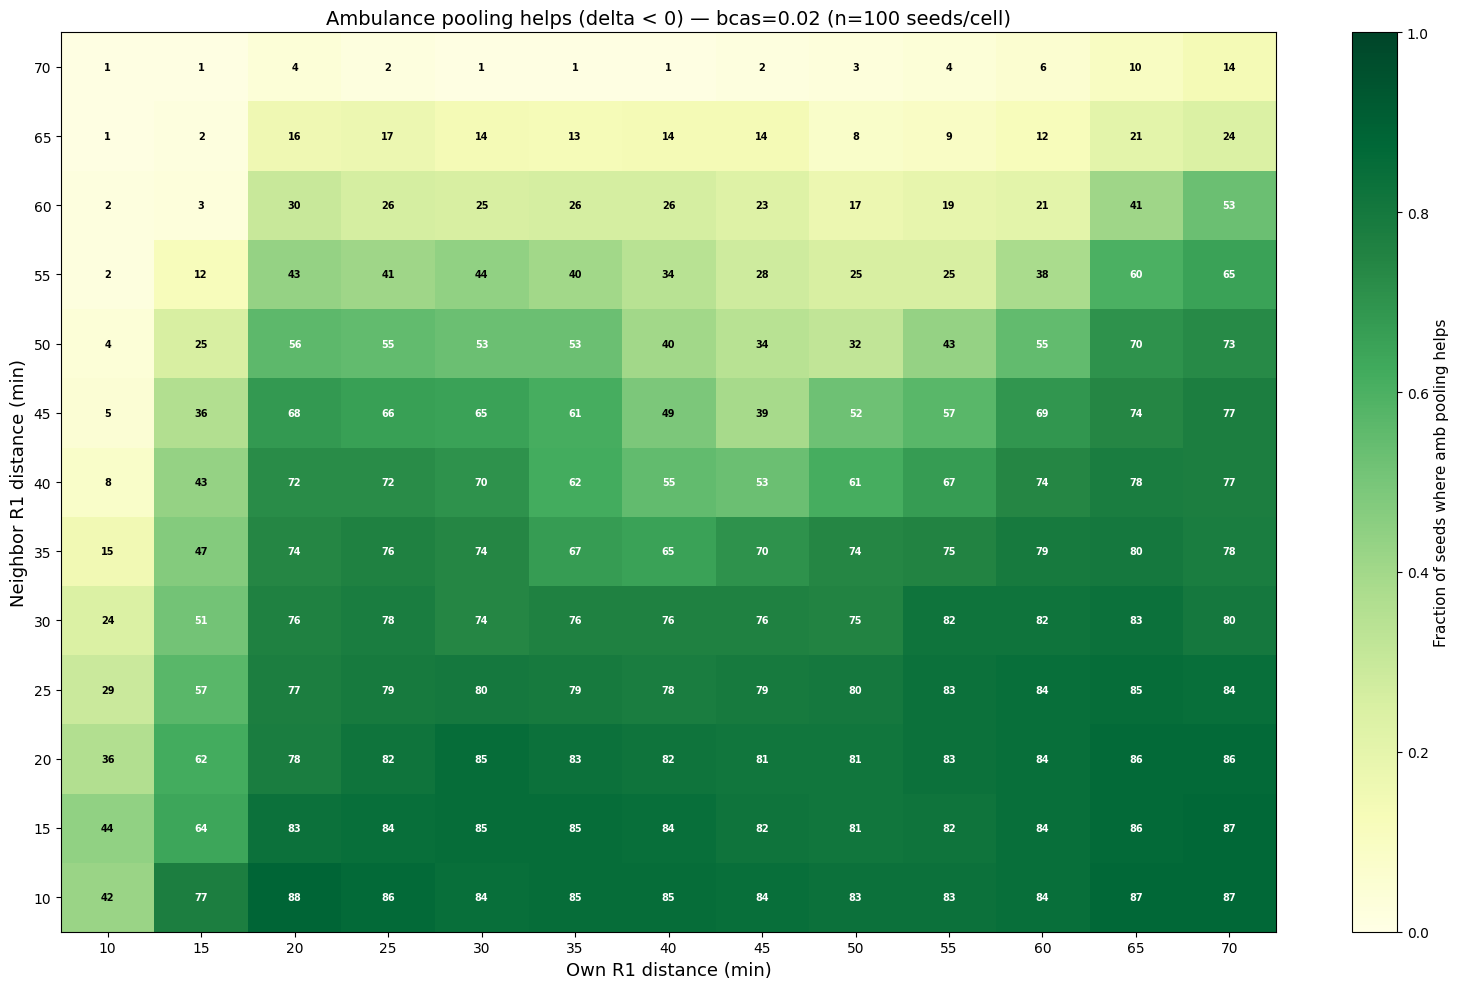

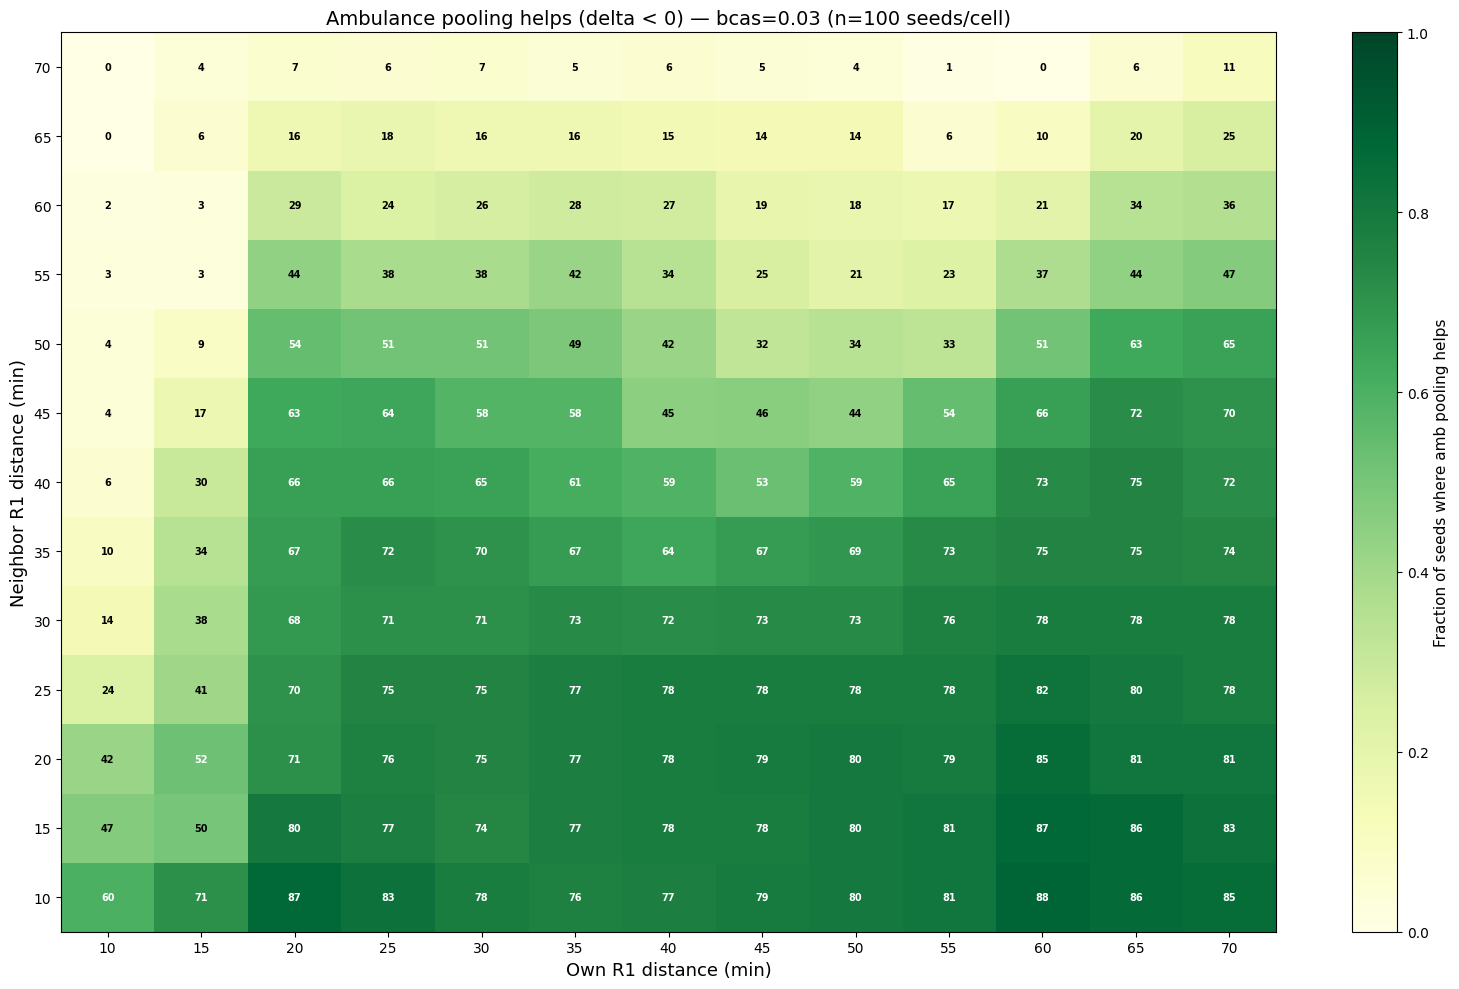

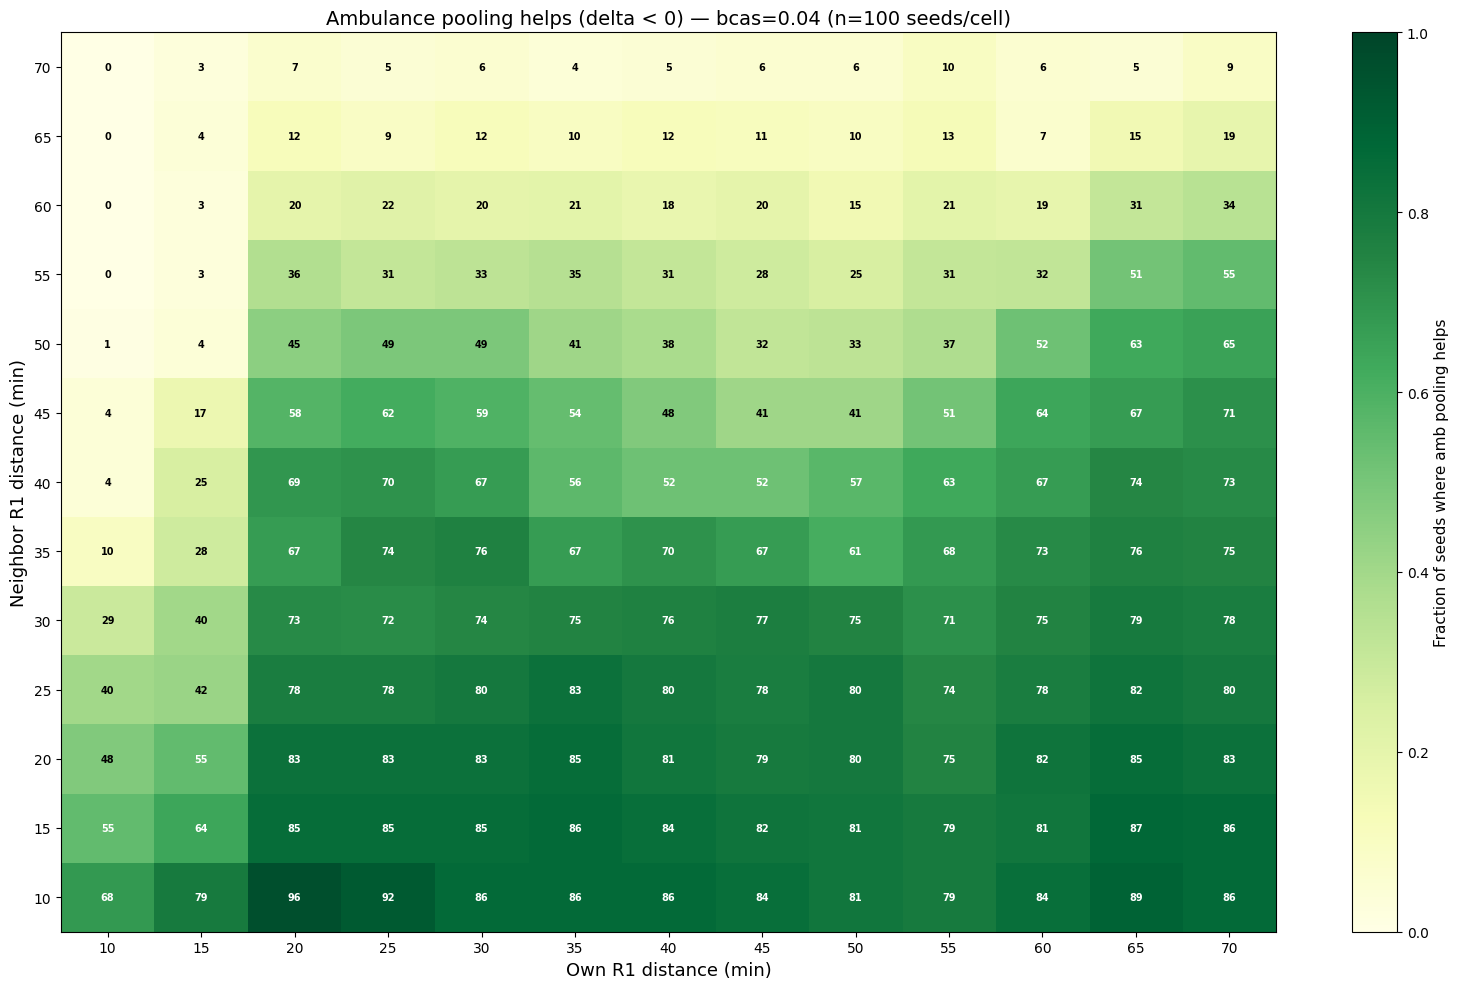

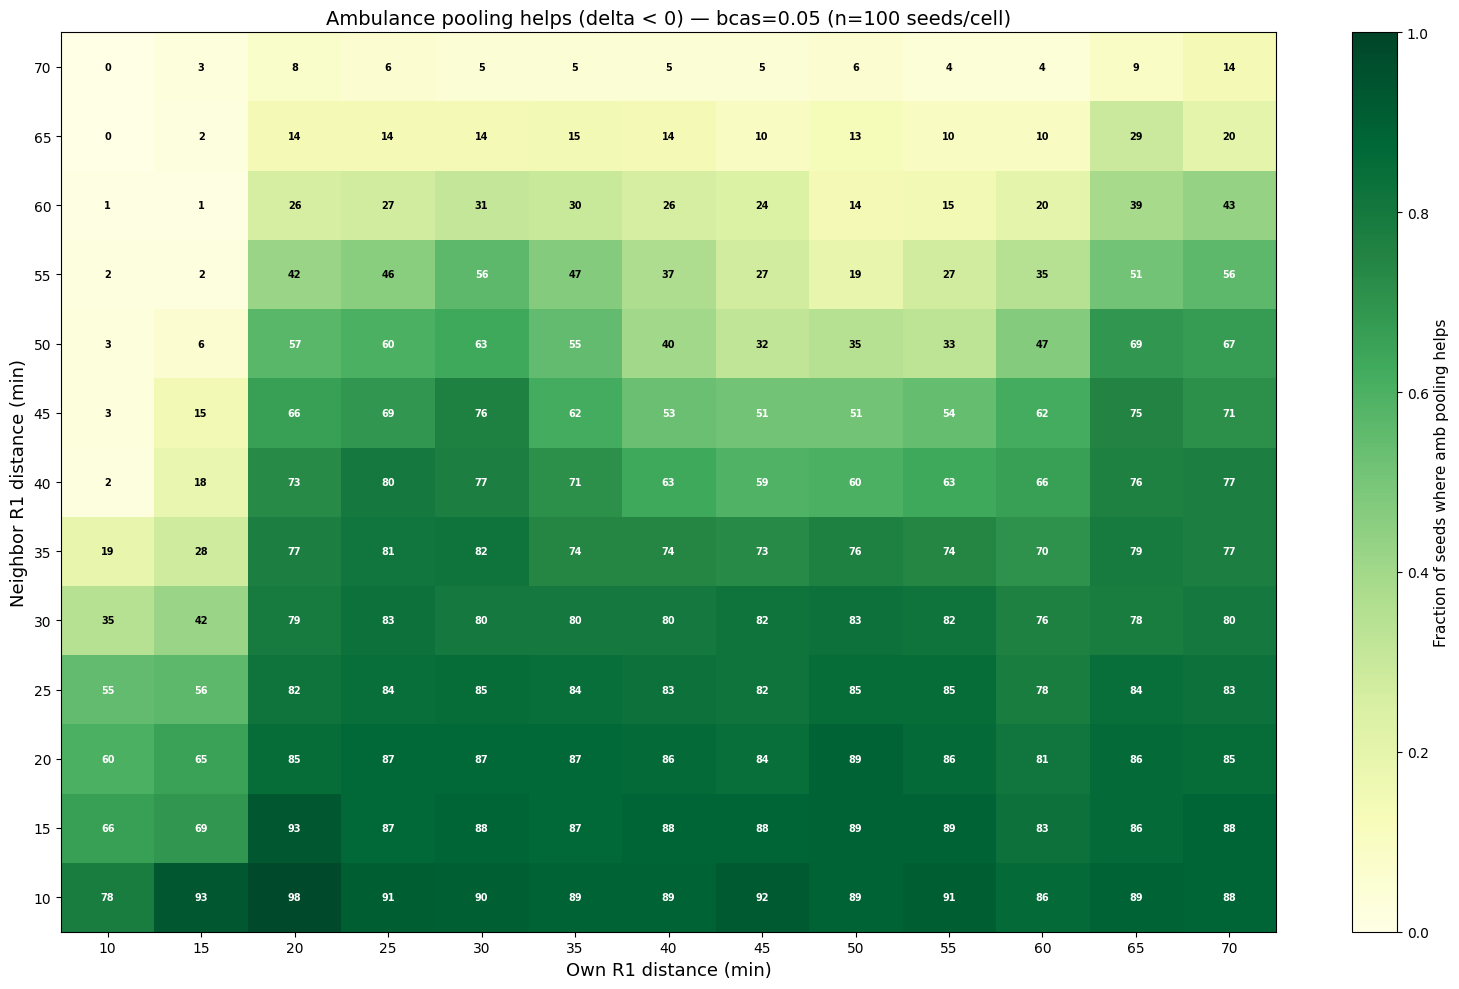

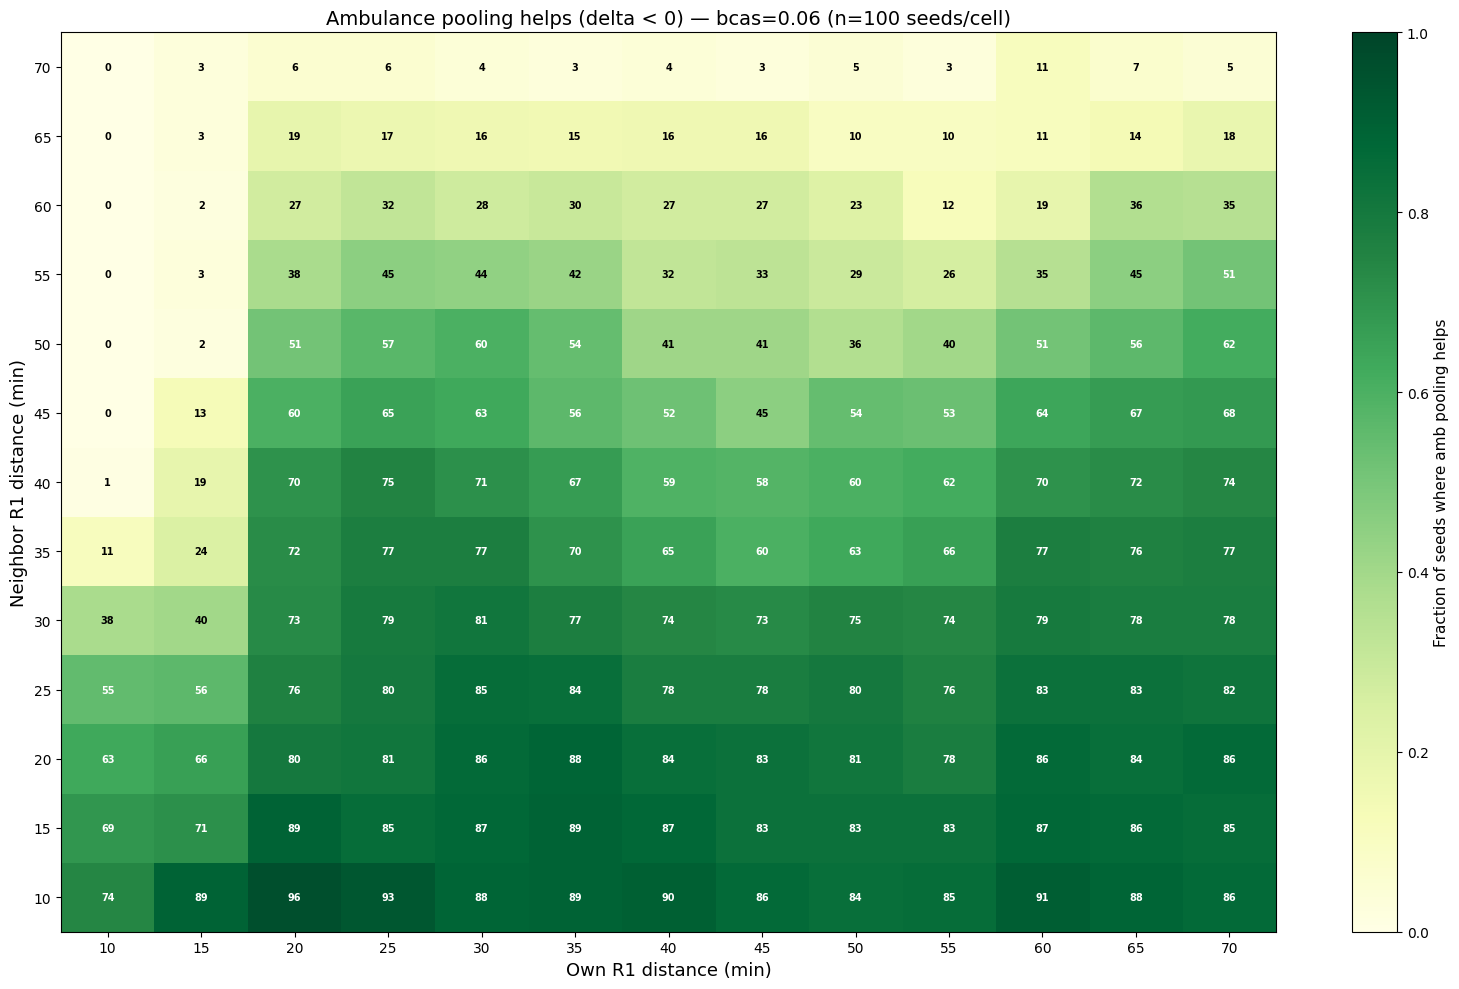

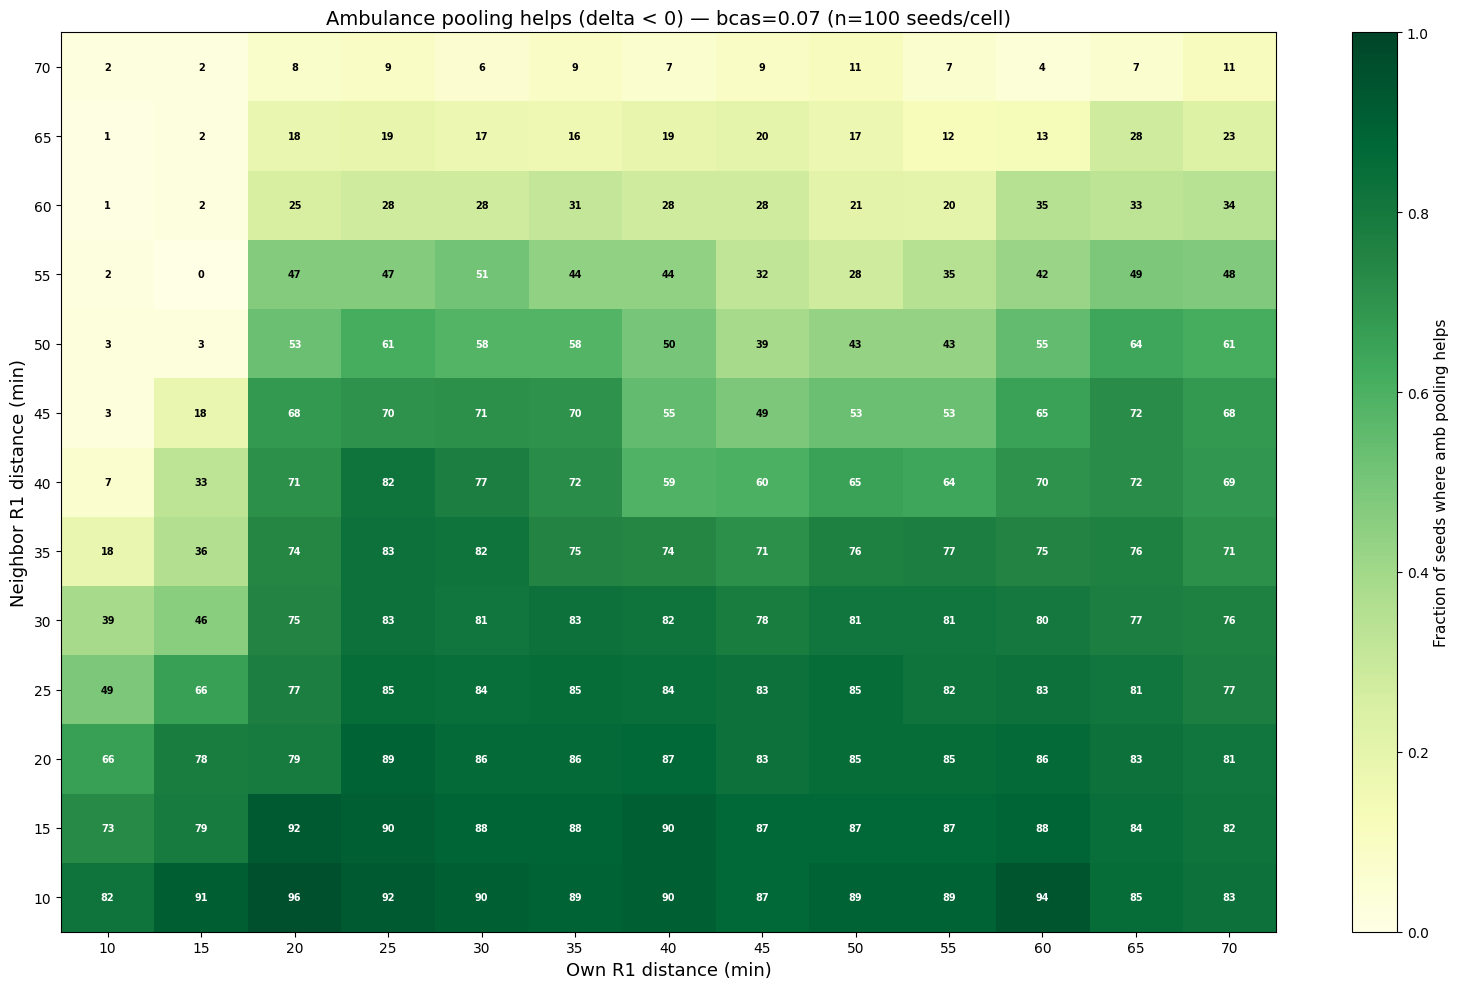

In [3]:
for bcas in sorted(df["bcas_rate"].unique()):
    s = stove[stove["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    p = policy[policy["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)

    merged = s[MATCH_COLS].copy()
    merged["delta"] = p["death_rate_T1_BCAS"].values - s["death_rate_T1_BCAS"].values
    merged["helps"] = merged["delta"] < 0

    grid = merged.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"]).agg(
        frac_helps=("helps", "mean"),
        n_helps=("helps", "sum"),
    ).reset_index()

    pivot_frac = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="frac_helps")
    pivot_n = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="n_helps")

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot_frac.values, cmap="YlGn", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=0, vmax=1)

    ax.set_xticks(range(len(pivot_frac.columns)))
    ax.set_xticklabels(pivot_frac.columns)
    ax.set_yticks(range(len(pivot_frac.index)))
    ax.set_yticklabels(pivot_frac.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Ambulance pooling helps (delta < 0) — bcas={bcas} (n=100 seeds/cell)", fontsize=14)

    for i in range(len(pivot_frac.index)):
        for j in range(len(pivot_frac.columns)):
            frac = pivot_frac.values[i, j]
            n = int(pivot_n.values[i, j])
            color = "white" if frac > 0.5 else "black"
            ax.text(j, i, f"{n}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Fraction of seeds where amb pooling helps", fontsize=11)
    plt.tight_layout()
    plt.show()


## Median delta (amb - stovepipe) per distance cell


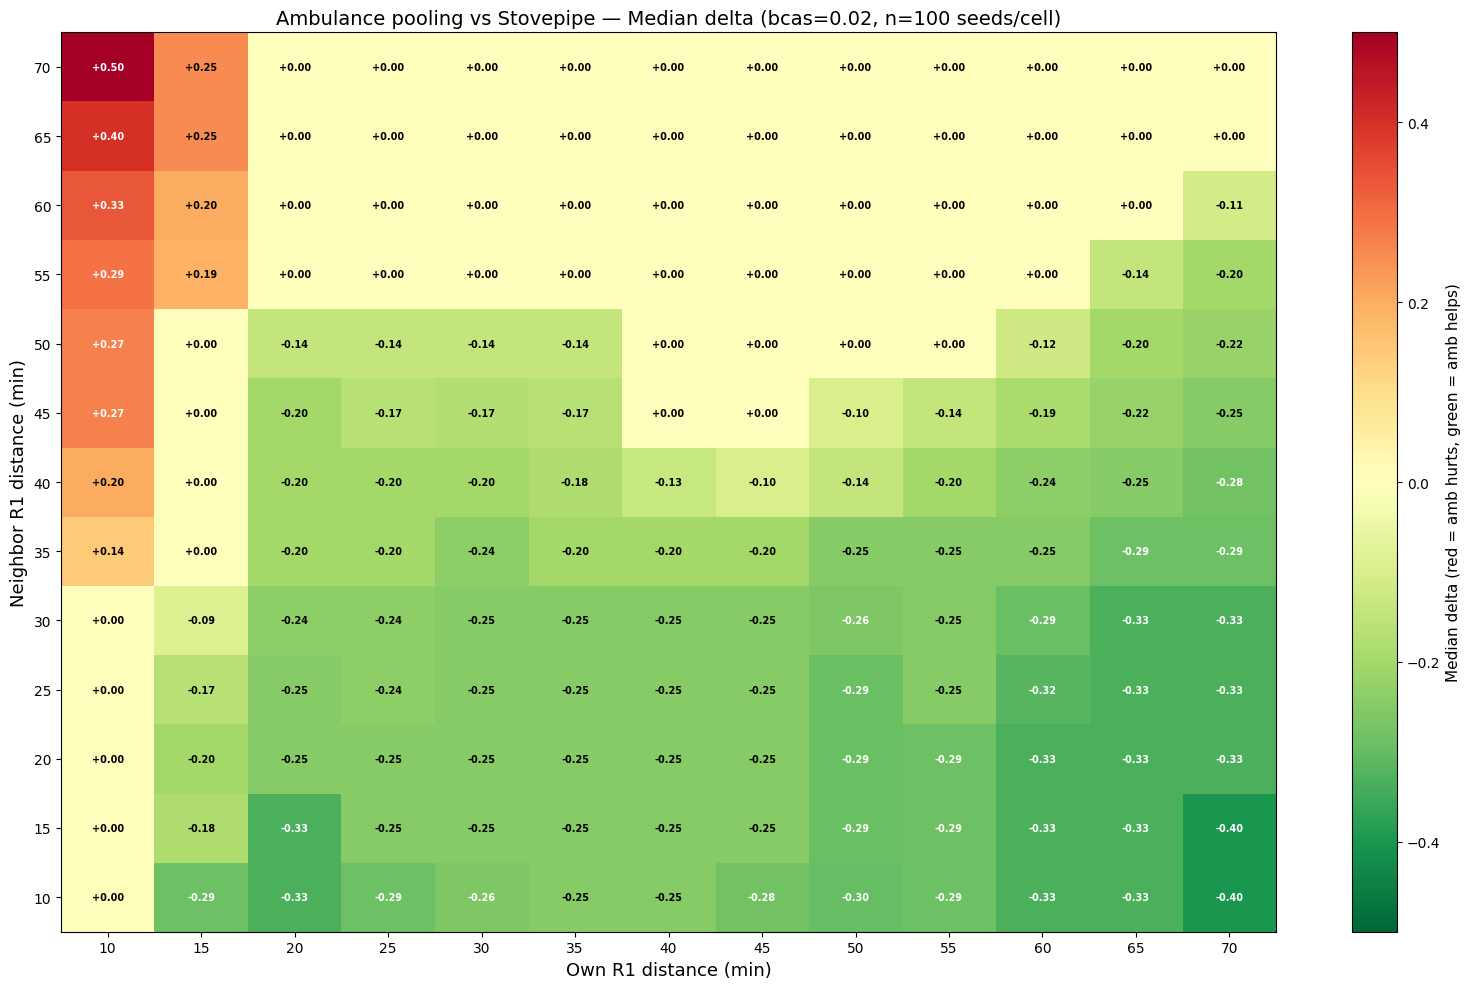

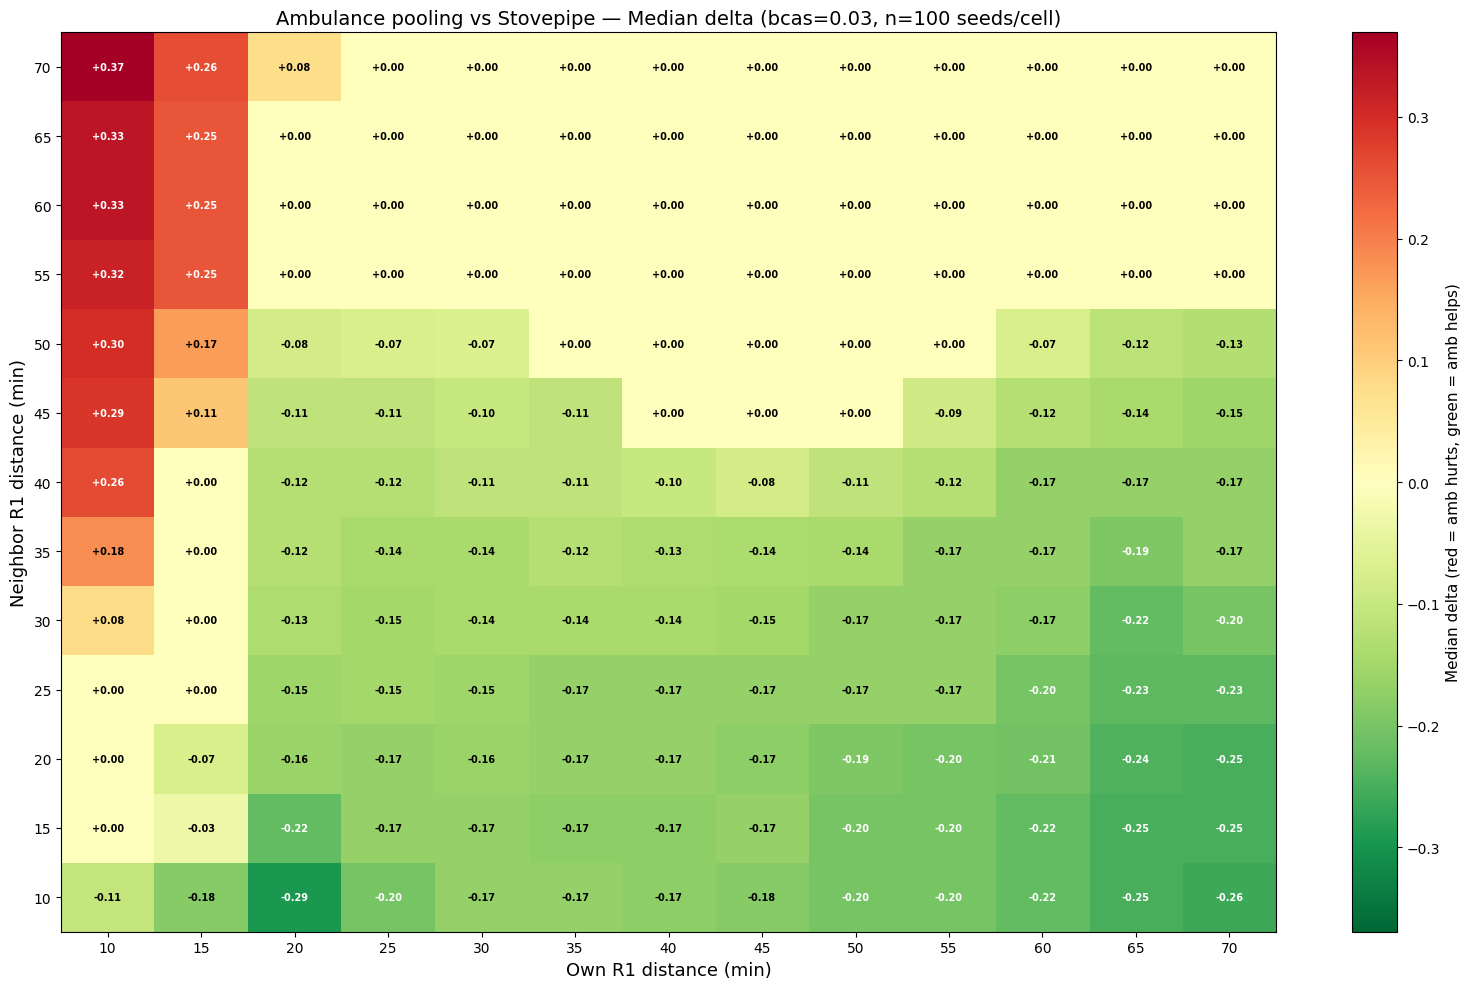

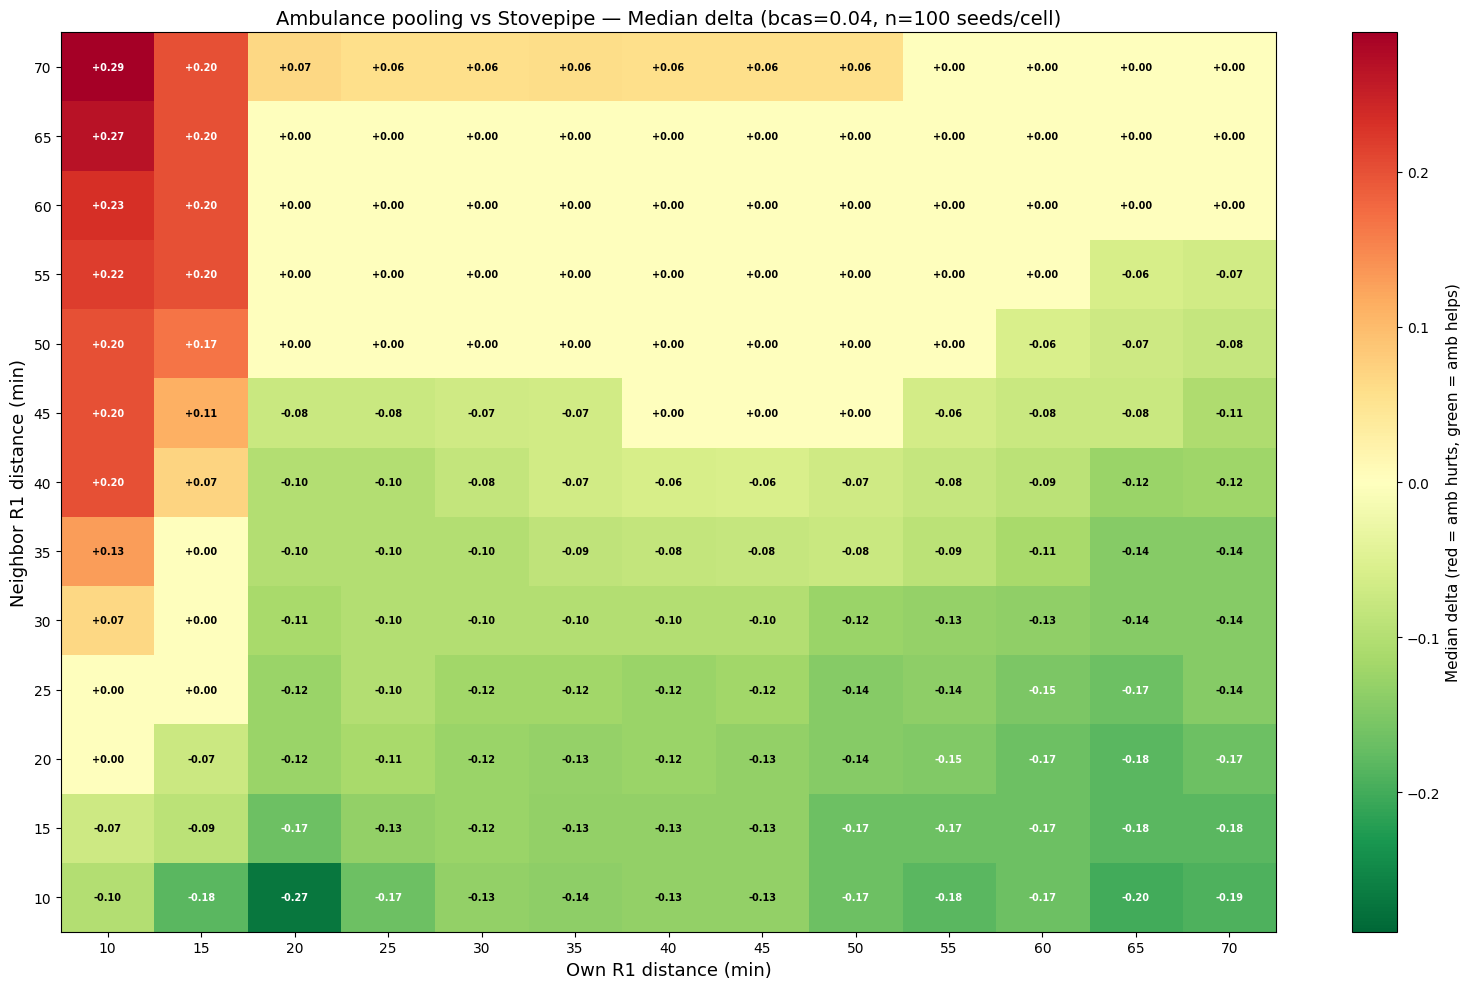

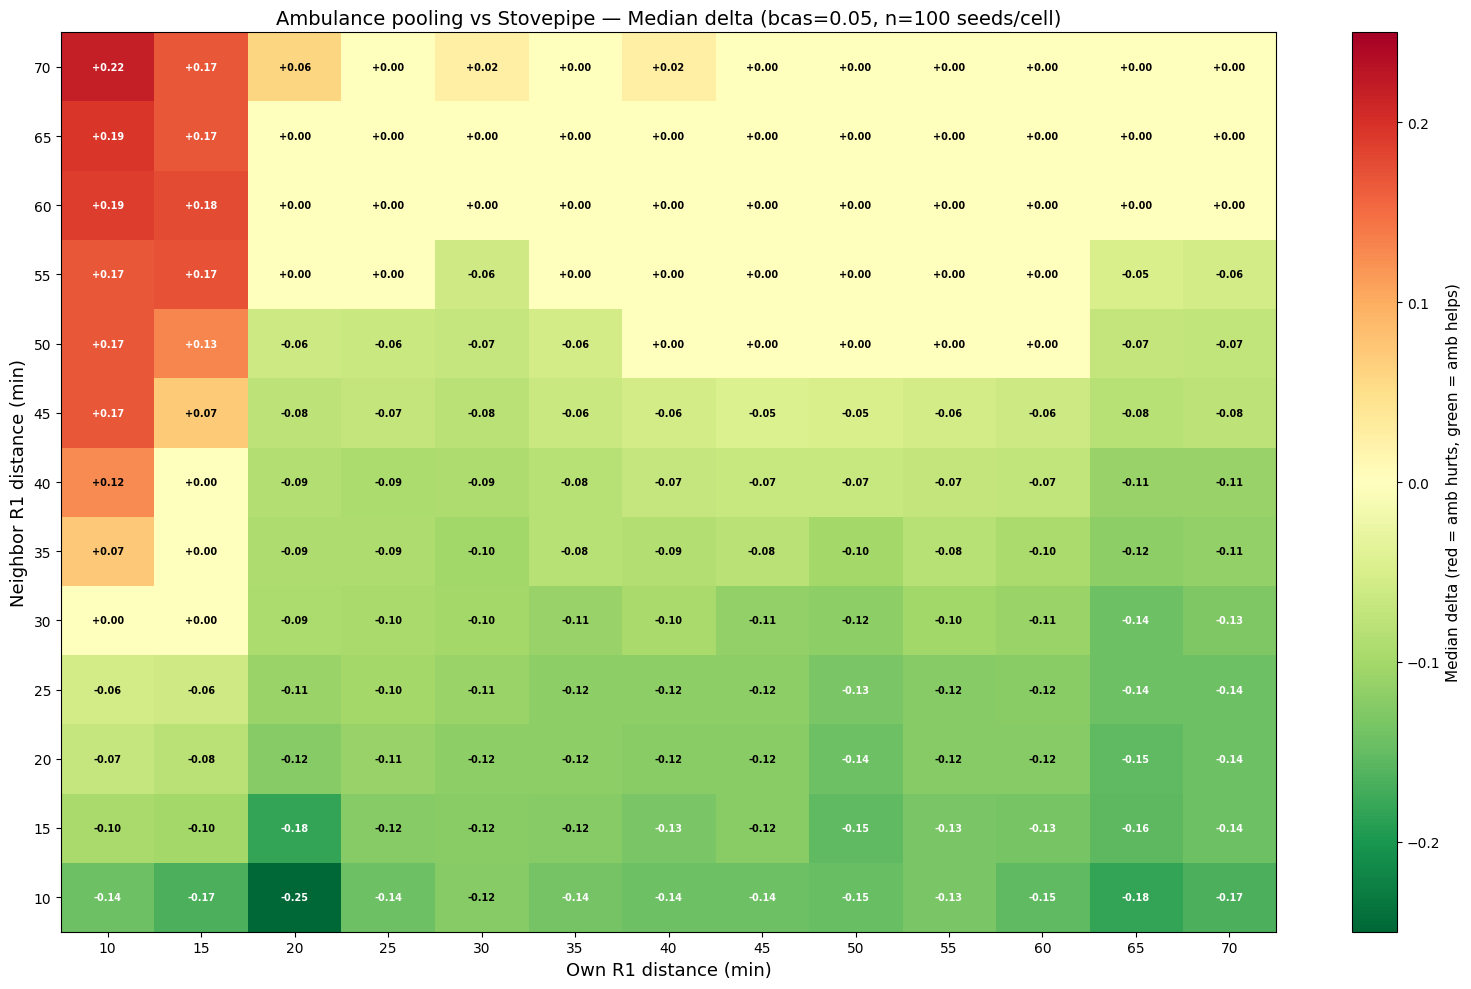

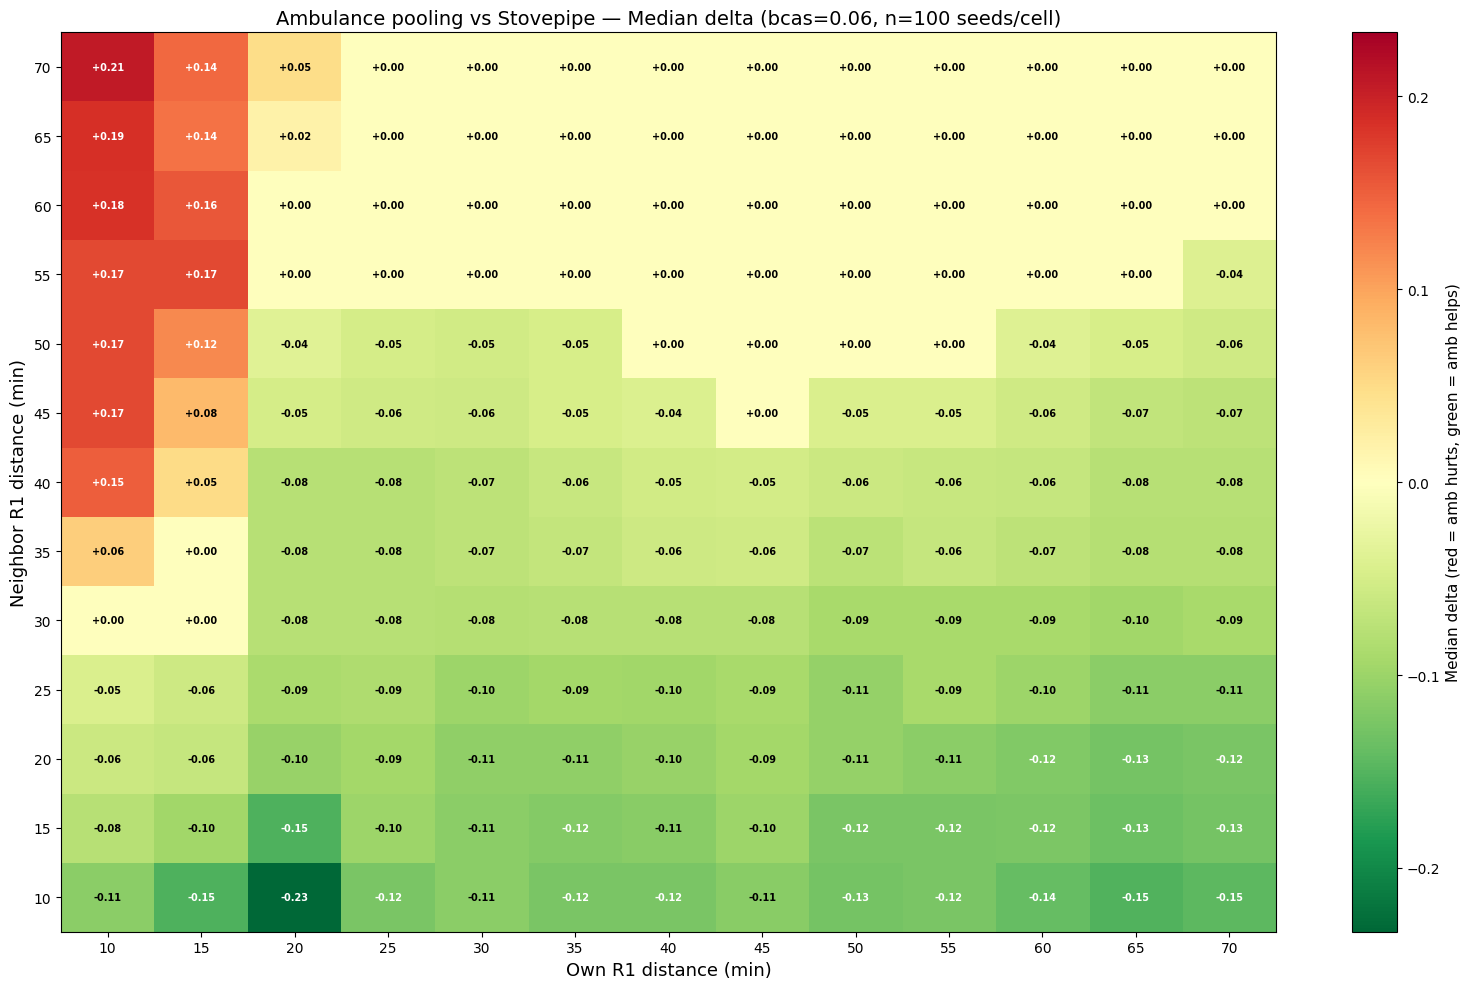

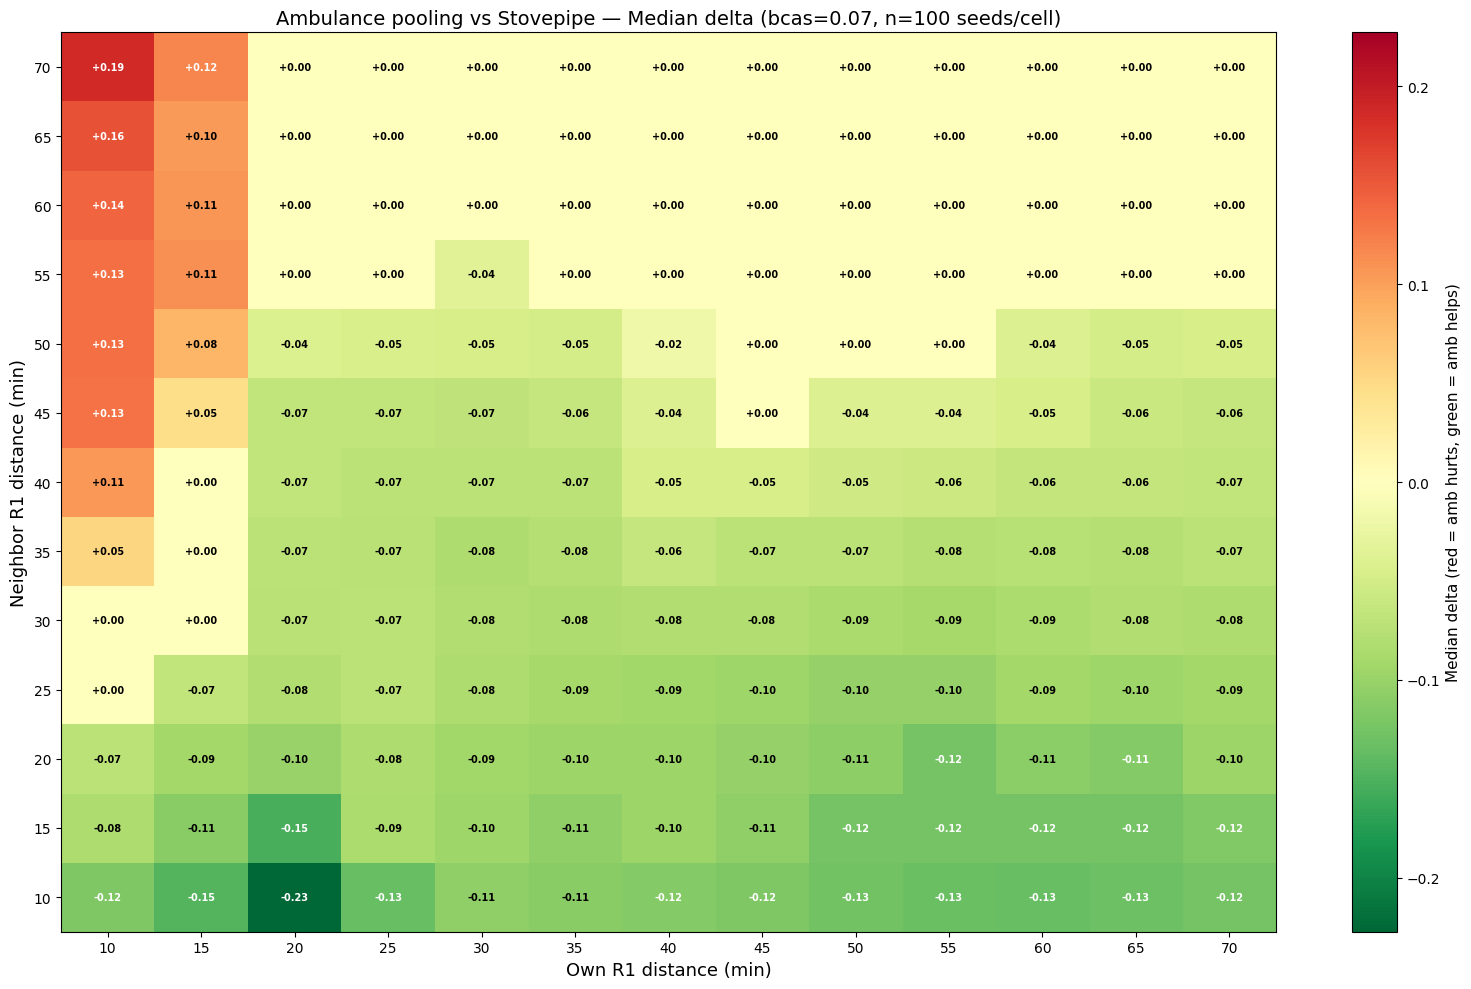

In [4]:
for bcas in sorted(df["bcas_rate"].unique()):
    s = stove[stove["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)
    p = policy[policy["bcas_rate"] == bcas].sort_values(MATCH_COLS).reset_index(drop=True)

    merged = s[MATCH_COLS].copy()
    merged["delta"] = p["death_rate_T1_BCAS"].values - s["death_rate_T1_BCAS"].values

    grid = merged.groupby(["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min"])["delta"].median().reset_index()
    pivot = grid.pivot(index="ccp_r1_inter_bn_min", columns="ccp_r1_same_bn_min", values="delta")

    vmax = max(abs(pivot.values.min()), abs(pivot.values.max()), 0.01)

    fig, ax = plt.subplots(figsize=(16, 10))
    im = ax.imshow(pivot.values, cmap="RdYlGn_r", origin="lower", aspect="auto",
                   interpolation="nearest", vmin=-vmax, vmax=vmax)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel("Own R1 distance (min)", fontsize=13)
    ax.set_ylabel("Neighbor R1 distance (min)", fontsize=13)
    ax.set_title(f"Ambulance pooling vs Stovepipe — Median delta (bcas={bcas}, n=100 seeds/cell)", fontsize=14)

    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            color = "white" if abs(val) > vmax * 0.5 else "black"
            ax.text(j, i, f"{val:+.2f}", ha="center", va="center", fontsize=7, fontweight="bold", color=color)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label("Median delta (red = amb hurts, green = amb helps)", fontsize=11)
    plt.tight_layout()
    plt.show()
